# Exploratory Data Analysis - Titanic Dataset

## Project Description

This notebook explores the Titanic dataset using Python,
Pandas, and Matplotlib.

The objective is to understand the dataset, identify patterns,
analyze missing values, and visualize relevant information.

In [1]:
# Import essential libraries for data manipulation and visualization
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Verify the project working directory and dataset availability
from pathlib import Path

print("Working directory:", Path.cwd())
print("Dataset available:", Path("train.csv").is_file())

Working directory: C:\Users\gmorando\Documents\Titanic_EDA_Project
Dataset available: True


In [3]:
# Load the Titanic dataset and inspect its initial records
df = pd.read_csv("train.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Assess dataset structure, data types, and data completeness
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [5]:
# Assess data completeness by identifying missing values across all features
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [6]:
# Quantify missing data proportions to assess potential data quality issues
(df.isna().sum() / len(df) * 100).round(2)

PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64

In [7]:
# Identify fully duplicated records to assess dataset integrity
duplicate_records = df.duplicated().sum()

print(f"Total duplicated records: {duplicate_records}")

Total duplicated records: 0


In [8]:
# Validate passenger identifier uniqueness to detect potential data inconsistencies
duplicate_passenger_ids = df["PassengerId"].duplicated().sum()

print(f"Duplicated Passenger IDs: {duplicate_passenger_ids}")

Duplicated Passenger IDs: 0


In [9]:
# Validate categorical values and numerical ranges to identify potential data quality issues
print("Survival categories:", sorted(df["Survived"].unique()))
print("Passenger classes:", sorted(df["Pclass"].unique()))
print("Gender categories:", df["Sex"].unique())

print("\nMinimum age:", df["Age"].min())
print("Maximum age:", df["Age"].max())

print("\nMinimum fare:", df["Fare"].min())
print("Maximum fare:", df["Fare"].max())

Survival categories: [np.int64(0), np.int64(1)]
Passenger classes: [np.int64(1), np.int64(2), np.int64(3)]
Gender categories: <ArrowStringArray>
['male', 'female']
Length: 2, dtype: str

Minimum age: 0.42
Maximum age: 80.0

Minimum fare: 0.0
Maximum fare: 512.3292


In [10]:
# Identify zero fares and invalid negative values to assess numerical data quality
print("Zero-fare records:", (df["Fare"] == 0).sum())
print("Negative fares:", (df["Fare"] < 0).sum())
print("Negative ages:", (df["Age"] < 0).sum())

Zero-fare records: 15
Negative fares: 0
Negative ages: 0


### Key Findings: Data Quality Assessment

- No fully duplicated records or duplicated passenger identifiers were detected.
- Survival status contains only the expected binary values (0 and 1).
- Passenger class contains the expected categories (1, 2, and 3).
- Gender contains two recorded categories: male and female.
- Passenger ages range from 0.42 to 80 years, with no negative values detected.
- Ticket fares range from 0 to 512.33, with no negative values detected.
- A total of 15 passengers (1.68%) have zero-fare records, which may require further investigation.
- Missing values were identified in Age (177), Cabin (687), and Embarked (2).
- No records were removed or modified during the initial data quality assessment.

In [11]:
# Examine descriptive statistics to understand numerical distributions and variability
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


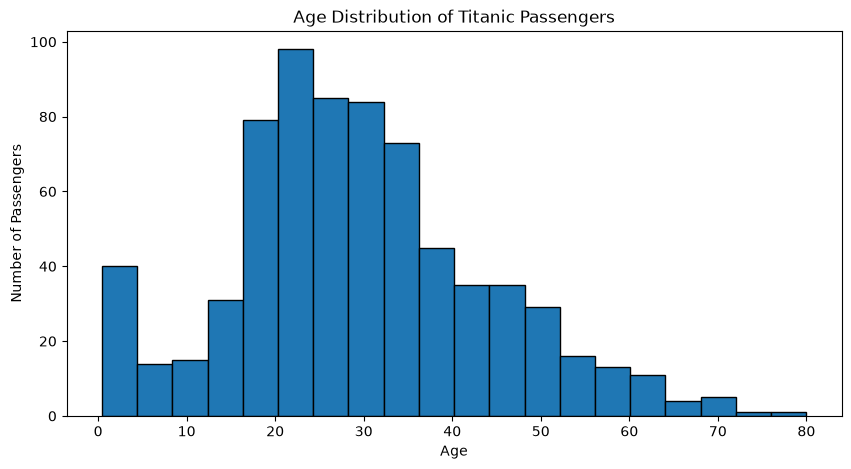

In [12]:
# Analyze passenger age distribution to identify demographic patterns
plt.figure(figsize=(10, 5))

plt.hist(df["Age"].dropna(), bins=20, edgecolor="black")

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

### Key Findings: Age Distribution

- Most passengers with recorded ages were young adults, primarily between 18 and 35 years old.
- The highest concentration of passengers was approximately between 20 and 24 years old.
- The average passenger age was 29.70 years, while the median was 28 years.
- The age distribution shows a slight right skew, with fewer passengers in older age groups.
- Age information is missing for 177 passengers (19.87%), which should be considered when interpreting the results.

In [13]:
# Assess survival outcomes by gender using passenger counts and survival rates
survival_by_gender = (
    df.groupby("Sex")["Survived"]
    .agg(
        total_passengers="count",
        survivors="sum",
        survival_rate="mean"
    )
)

survival_by_gender["survival_rate"] = (
    survival_by_gender["survival_rate"] * 100
).round(2)

survival_by_gender

,total_passengers,survivors,survival_rate
Sex,,,
female,314,233,74.20
male,577,109,18.89


In [14]:
# Assess survival outcomes by gender using passenger counts and survival rates
survival_by_gender = (
    df.groupby("Sex")["Survived"]
    .agg(
        total_passengers="count",
        survivors="sum",
        survival_rate="mean"
    )
)

survival_by_gender["survival_rate"] = (
    survival_by_gender["survival_rate"] * 100
).round(2)

survival_by_gender

,total_passengers,survivors,survival_rate
Sex,,,
female,314,233,74.20
male,577,109,18.89


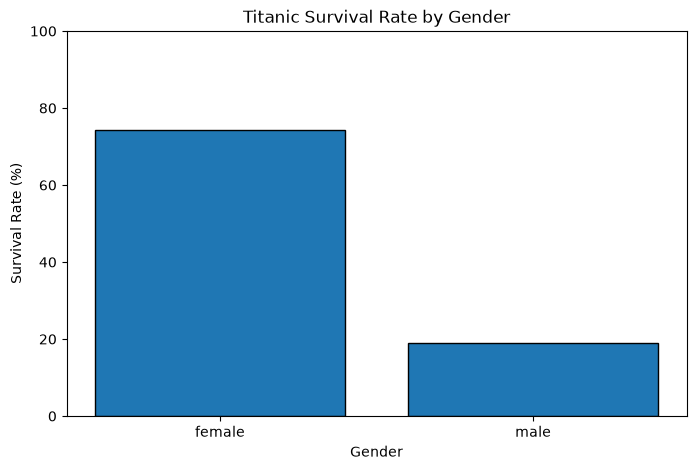

In [15]:
# Visualize survival rate disparities by gender to highlight outcome differences
plt.figure(figsize=(8, 5))

plt.bar(
    survival_by_gender.index,
    survival_by_gender["survival_rate"],
    edgecolor="black"
)

plt.title("Titanic Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

plt.show()

### Key Findings: Survival by Gender

- Female passengers had a survival rate of 74.20%, compared with 18.89% for male passengers.
- The difference between both groups was 55.31 percentage points.
- Although male passengers outnumbered female passengers, more women survived in absolute terms.
- Gender was strongly associated with survival outcomes in this dataset.
- Further analysis is needed to examine whether this relationship varies across passenger classes.

In [16]:
# Evaluate survival outcomes across passenger classes to identify socioeconomic disparities
survival_by_class = (
    df.groupby("Pclass")["Survived"]
    .agg(
        total_passengers="count",
        survivors="sum",
        survival_rate="mean"
    )
)

survival_by_class["survival_rate"] = (
    survival_by_class["survival_rate"] * 100
).round(2)

survival_by_class

,total_passengers,survivors,survival_rate
Pclass,,,
1,216,136,62.96
2,184,87,47.28
3,491,119,24.24


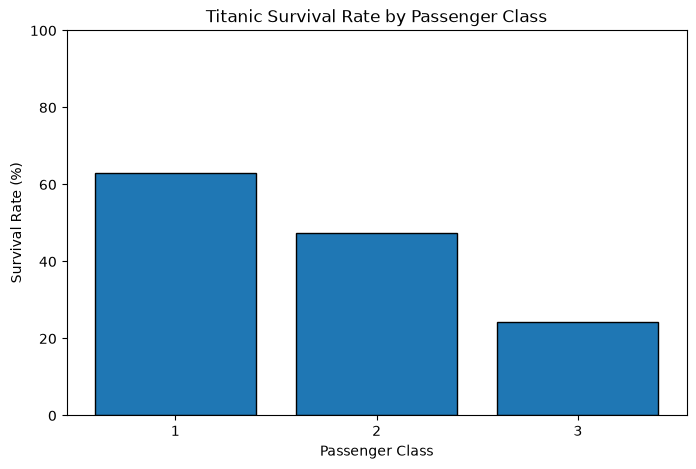

In [17]:
# Visualize survival rate differences across passenger classes
plt.figure(figsize=(8, 5))

plt.bar(
    survival_by_class.index.astype(str),
    survival_by_class["survival_rate"],
    edgecolor="black"
)

plt.title("Titanic Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)

plt.show()

### Key Findings: Survival by Passenger Class

- First-class passengers had the highest survival rate (62.96%), followed by second-class passengers (47.28%).
- Third-class passengers had the lowest survival rate (24.24%), despite representing the largest passenger group.
- The survival rate difference between first and third class was 38.72 percentage points.
- First-class passengers had approximately 2.6 times the survival rate of third-class passengers.
- These findings suggest an association between passenger class and survival, but do not establish a causal relationship.

In [18]:
# Examine survival disparities across gender and passenger class segments
survival_by_class_gender = (
    df.groupby(["Pclass", "Sex"])["Survived"]
    .agg(
        total_passengers="count",
        survivors="sum",
        survival_rate="mean"
    )
)

survival_by_class_gender["survival_rate"] = (
    survival_by_class_gender["survival_rate"] * 100
).round(2)

survival_by_class_gender

total_passengers  survivors  survival_rate
Pclass Sex                                               
1      female                94         91          96.81
       male                 122         45          36.89
2      female                76         70          92.11
       male                 108         17          15.74
3      female               144         72          50.00
       male                 347         47          13.54

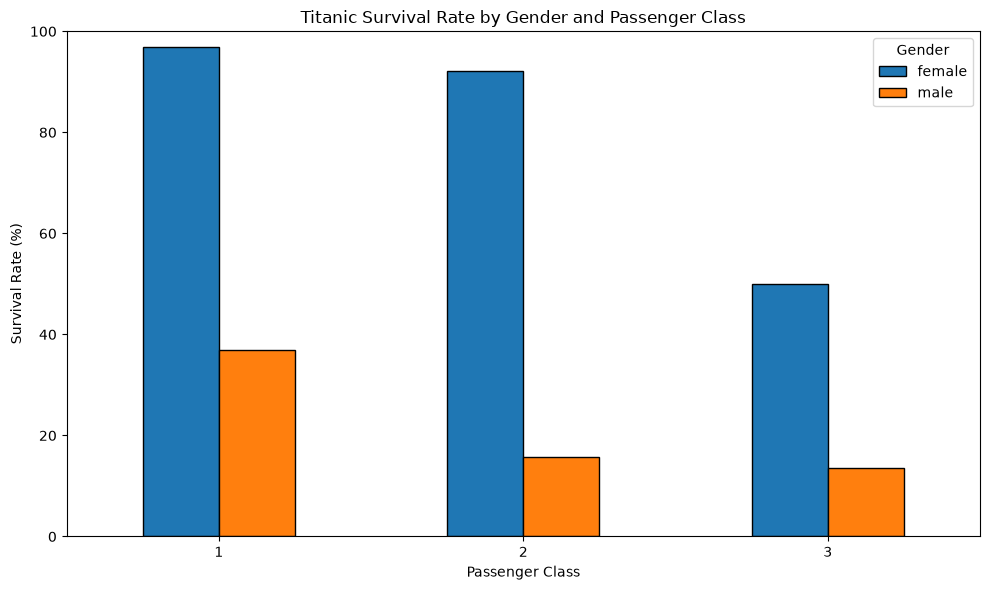

In [19]:
# Compare gender-based survival rates within each passenger class
survival_comparison = (
    survival_by_class_gender["survival_rate"]
    .unstack()
)

survival_comparison.plot(
    kind="bar",
    figsize=(10, 6),
    edgecolor="black"
)

plt.title("Titanic Survival Rate by Gender and Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Gender")
plt.tight_layout()

plt.show()

### Key Findings: Survival by Gender and Passenger Class

- Female passengers consistently had higher survival rates than male passengers across all three classes.
- First-class women recorded the highest survival rate (96.81%), while third-class men had the lowest (13.54%).
- The largest gender gap occurred in second class, with a difference of 76.37 percentage points.
- Third-class women had a higher survival rate (50.00%) than first-class men (36.89%).
- These findings highlight the importance of examining gender and passenger class together when analyzing survival outcomes.
- The observed relationships are descriptive and do not establish causality.

In [20]:
# Compare age distributions between survivors and non-survivors
age_by_survival = (
    df.groupby("Survived")["Age"]
    .agg(
        passengers_with_age="count",
        mean_age="mean",
        median_age="median",
        min_age="min",
        max_age="max",
        age_std="std"
    )
    .round(2)
)

age_by_survival

,passengers_with_age,mean_age,median_age,min_age,max_age,age_std
Survived,,,,,,
0,424,30.63,28.0,1.00,74.0,14.17
1,290,28.34,28.0,0.42,80.0,14.95


In [21]:
# Assess survival patterns across age groups to identify demographic differences
age_groups = pd.cut(
    df["Age"],
    bins=[0, 10, 20, 30, 40, 50, 60, 70, 81],
    labels=["0-9", "10-19", "20-29", "30-39",
        "40-49", "50-59", "60-69", "70-80"],
    right=False,
    include_lowest=True
)

survival_by_age = (
    df.groupby(age_groups, observed=False)["Survived"]
    .agg(
        total_passengers="count",
        survivors="sum",
        survival_rate="mean"
    )
)

survival_by_age["survival_rate"] = (
    survival_by_age["survival_rate"] * 100
).round(2)

survival_by_age

,total_passengers,survivors,survival_rate
Age,,,
0-9,62,38,61.29
10-19,102,41,40.20
20-29,220,77,35.00
30-39,167,73,43.71
40-49,89,34,38.20
50-59,48,20,41.67
60-69,19,6,31.58
70-80,7,1,14.29


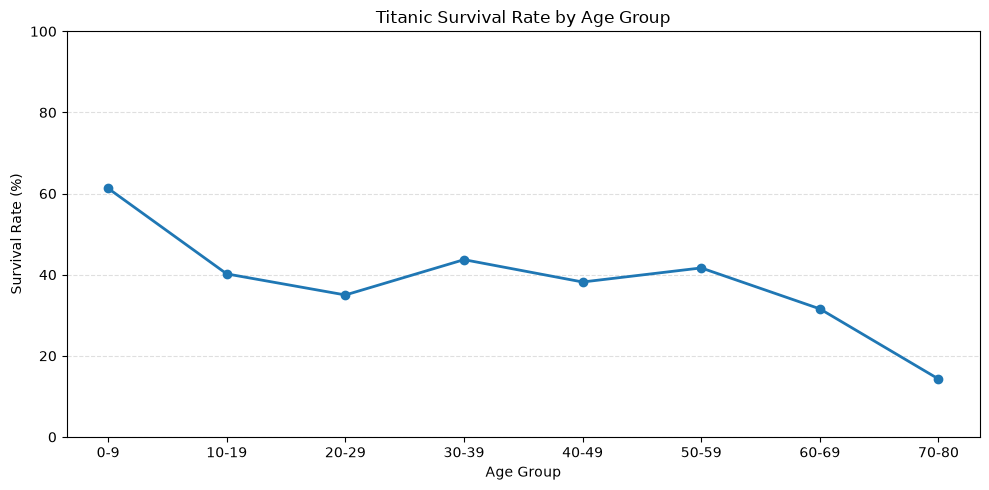

In [22]:
# Visualize age-specific survival rates to identify demographic trends
plt.figure(figsize=(10, 5))

plt.plot(
    survival_by_age.index.astype(str),
    survival_by_age["survival_rate"],
    marker="o",
    linewidth=2
)

plt.title("Titanic Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()

### Key Findings: Survival by Age Group

- Children aged 0–9 had the highest observed survival rate (61.29%).
- Passengers aged 20–29 represented the largest age group (220 passengers), with a survival rate of 35.00%.
- Survival rates fluctuated across adult age groups, suggesting no clear linear relationship between age and survival.
- Passengers aged 70–80 had the lowest observed survival rate (14.29%), although this group contained only seven passengers.
- Missing age values (177 records, 19.87%) and small sample sizes in older age groups should be considered when interpreting these findings.
- These results indicate an association between age groups and survival outcomes but do not establish causality.

In [23]:
# Compare ticket fare distributions between survivors and non-survivors
fare_by_survival = (
    df.groupby("Survived")["Fare"]
    .agg(
        total_passengers="count",
        mean_fare="mean",
        median_fare="median",
        min_fare="min",
        max_fare="max",
        fare_std="std"
    )
    .round(2)
)

fare_by_survival

,total_passengers,mean_fare,median_fare,min_fare,max_fare,fare_std
Survived,,,,,,
0,549,22.12,10.5,0.0,263.00,31.39
1,342,48.40,26.0,0.0,512.33,66.60


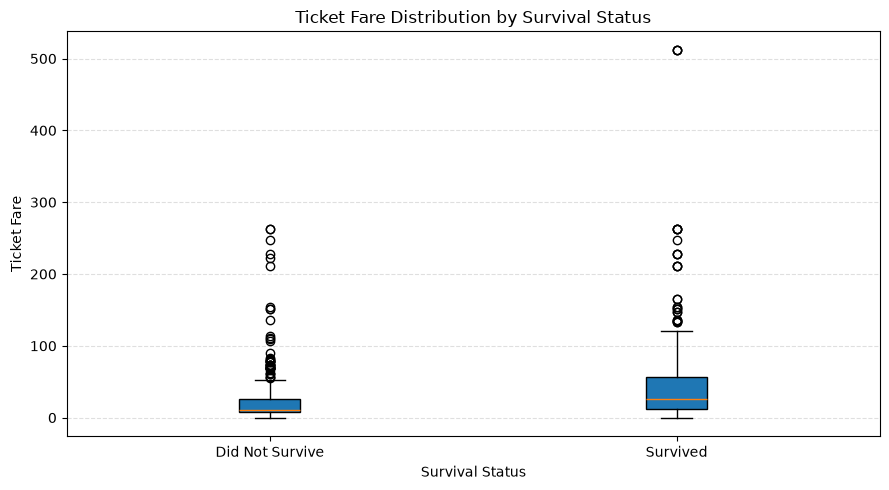

In [24]:
# Compare ticket fare distributions and identify potential outliers by survival status
plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        df.loc[df["Survived"] == 0, "Fare"].dropna(),
        df.loc[df["Survived"] == 1, "Fare"].dropna()
    ],
    tick_labels=["Did Not Survive", "Survived"],
    patch_artist=True
)

plt.title("Ticket Fare Distribution by Survival Status")
plt.xlabel("Survival Status")
plt.ylabel("Ticket Fare")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()

### Key Findings: Ticket Fare and Survival

- Survivors paid higher ticket fares on average (48.40) than non-survivors (22.12).
- The median fare was also higher among survivors (26.00) compared with non-survivors (10.50).
- Ticket fares exhibited substantial right-skewness and multiple potential outliers.
- Fare variability was greater among survivors, as reflected by a higher standard deviation.
- These findings suggest an association between ticket fare and survival, although passenger class and other factors may influence this relationship.

In [25]:
# Compare ticket fare distributions by passenger class and survival status
fare_by_class_survival = (
    df.groupby(["Pclass", "Survived"])["Fare"]
    .agg(
        total_passengers="count",
        mean_fare="mean",
        median_fare="median",
        min_fare="min",
        max_fare="max"
    )
    .round(2)
)

fare_by_class_survival

total_passengers  mean_fare  median_fare  min_fare  max_fare
Pclass Survived                                                              
1      0                       80      64.68        44.75      0.00    263.00
       1                      136      95.61        77.96     25.93    512.33
2      0                       97      19.41        13.00      0.00     73.50
       1                       87      22.06        21.00     10.50     65.00
3      0                      372      13.67         8.05      0.00     69.55
       1                      119      13.69         8.52      0.00     56.50

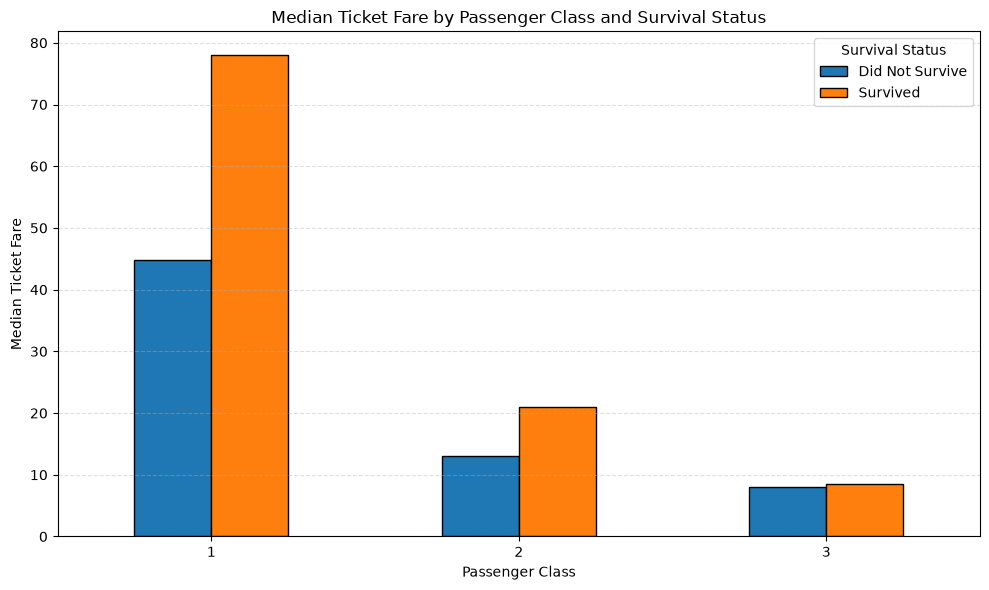

In [26]:
# Compare median ticket fares by passenger class and survival status
median_fare_comparison = (
    fare_by_class_survival["median_fare"]
    .unstack()
)

median_fare_comparison.columns = [
    "Did Not Survive",
    "Survived"
]

median_fare_comparison.plot(
    kind="bar",
    figsize=(10, 6),
    edgecolor="black"
)

plt.title("Median Ticket Fare by Passenger Class and Survival Status")
plt.xlabel("Passenger Class")
plt.ylabel("Median Ticket Fare")
plt.xticks(rotation=0)
plt.legend(title="Survival Status")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.show()

### Key Findings: Ticket Fare by Passenger Class and Survival

- First-class survivors had a substantially higher median fare (77.96) than non-survivors (44.75).
- In second class, survivors also had a higher median fare (21.00) compared with non-survivors (13.00).
- Third-class passengers showed minimal differences in median fares between survivors (8.52) and non-survivors (8.05).
- The relationship between ticket fare and survival varied considerably across passenger classes.
- These findings suggest that passenger class is an important factor to consider when interpreting the overall association between ticket fares and survival.
- The observed differences are descriptive and do not establish causality.

### Key Findings: Duplicate Records Validation

- No fully duplicated records were identified among the 891 observations.
- All PassengerId values are unique, supporting the integrity of passenger identifiers.
- No duplicate removal was required.
- Additional data quality checks are necessary to assess valid ranges, categorical values, and missing information.

## Overall Findings and Conclusions

### 1. Gender and Survival
- Female passengers had a substantially higher survival rate (74.20%) than male passengers (18.89%).
- The gender disparity was observed across all three passenger classes.

### 2. Passenger Class and Survival
- First-class passengers had the highest survival rate (62.96%), followed by second class (47.28%) and third class (24.24%).
- Survival outcomes varied considerably across passenger classes.

### 3. Age and Survival
- Children aged 0–9 had a survival rate of 61.29% among passengers with recorded ages.
- The 20–29 age group had a survival rate of 35.00%.
- Age-related findings should be interpreted cautiously because 177 age values are missing and some age groups have small sample sizes.

### 4. Ticket Fare and Survival
- Survivors paid higher average fares (48.40) than non-survivors (22.12).
- Fare differences varied by passenger class and were minimal in third class.
- These descriptive associations do not establish causality.

### 5. Data Quality and Limitations
- No duplicate records or duplicated passenger identifiers were detected.
- Missing values were identified in Age (177), Cabin (687), and Embarked (2).
- Fifteen zero-fare records were retained for potential further investigation.
- No data cleaning transformations were applied during this exploratory assessment.

### Final Conclusion
Gender and passenger class showed substantial differences in survival rates. Age and ticket fare also exhibited relevant patterns, although missing data, unequal group sizes, and potential confounding factors limit causal interpretation.